# Изучение пользовательского спроса сервиса Яндекс Афиша

* Автор: Макарова Екатерина
* Дата: 09.10.2026 г.

#  Цель исследования:
Выявить инсайты об изменении пользовательских предпочтений и популярности событий осенью 2024 года.

# Задачи исследования:
1. Загрузить данные и познакомиться с их содержимым.
2. Провести предобработку данных.
3. Провести исследовательский анализ данных:
 * Сравнить распределения заказов по сегментам и их сезонные колебания.
 * Изучить осенную активность пользователей: посмотреть динамику изменений ключевых показателей по дням и выделить недельную цикличность (активность в будние и выходные).
 * Выявить ключевые регионы и партнёров, которые вносят наибольший вклад в выручку.
4. Подвести итоговые выводы и дать рекомендации - на что обратить внимание. 
---

# Описание данных
Для анализа используем данные о бронировании билетов на сервисе Яндекс Афиша за период с 1 июня по 31 октября 2024 года. Данные состоят из трех датасетов:
* `tickets_orders` - содержит информацию обо всех заказах билетов, совершённых с двух типов устройств — мобильных и стационарных. 
* `tickets_events` - содержит информацию о событиях, включая город и регион события, а также информацию о площадке проведения мероприятия. 
* `tickets_tenge` - содержит информацию о курсе тенге к российскому рублю за 2024 год. Значения в рублях представлено для 100 тенге.

***Описание датасета `tickets_orders`:***
* `order_id` — уникальный идентификатор заказа.
* `user_id` — уникальный идентификатор пользователя.
* `created_dt_msk` — дата создания заказа (московское время).
* `created_ts_msk` — дата и время создания заказа (московское время).
* `event_id` — идентификатор мероприятия.
* `cinema_circuit` — сеть кинотеатров. Если не применимо, то здесь будет значение 'нет'.
* `age_limit` — возрастное ограничение мероприятия.
* `currency_code` — валюта оплаты, например `rub` для российских рублей.
* `device_type_canonical` — тип устройства, с которого был оформлен заказ, например `mobile` для мобильных устройств, `desktop` для стационарных.
* `revenue` — выручка от заказа.
* `service_name` — название билетного оператора.
* `tickets_count` — количество купленных билетов.
* `total` — общая сумма заказа.
* `days_since_prev` - количество дней с предыдущей покупки для каждого пользователя. Если покупки не было, то данные содержат пропуск.

***Описание датасета `tickets_events`:***
* `event_id` — уникальный идентификатор мероприятия.
* `event_name` — название мероприятия. 
* `event_type_description` — описание типа мероприятия.
* `event_type_main` — основной тип мероприятия: театральная постановка, концерт и так далее.
* `organizers` — организаторы мероприятия.
* `region_name` — название региона.
* `city_name` — название города.
* `venue_id` — уникальный идентификатор площадки.
* `venue_name` — название площадки.
* `venue_address` — адрес площадки.

***Описание датасета `tickets_tenge`:***
* `nominal` — номинал (100 тенге);
* `data` — дата;
* `curs` — курс тенге к рублю;
* `cdx` — обозначение валюты (kzt).
---

<a id='start'></a>
# Содержание:

***ЧАСТЬ 1. Изучение общей информации:***

[1.1 Загрузка данных и знакомство с ними](#1.1)

***ЧАСТЬ 2. Предобработка данных:***

[2.1 Подготовка единого датафрейма](#2.1)

[2.2 Оптимизация типов данных](#2.2)

[2.3 Наличие пропусков в данных](#2.3)

[2.4 Проверка значений в ключевых данных](#2.4)

[2.5 Явные и неявные дубликаты в данных](#2.5)

[2.6 Создание новых столбцов](#2.6)

***ЧАСТЬ 3. Исследовательский анализ данных:***

[3.1 Анализ распределения заказов по сегментам и их сезонные изменения](#3.1)

[3.2 Осенняя активность пользователей](#3.2)

[3.3  Популярные события и партнёры](#3.3)

***ЧАСТЬ 4. Итоговый вывод и рекомендации:***

[4.1 Обзор проделанной работы](#5.1)

[4.2 Ответы на исследовательские вопросы](#5.2)

[4.3 Рекомендации на основе анализа данных](#5.4)

---

## Изучение общей информации
<a id='1.1'></a>
### Загрузка данных и знакомство с ними

Начнём с загрузки библиотек и данных по проекту. Данные датасетов сохраним в трех переменных: `df_orders`, `df_events` и `df_tenge`.

In [1]:
# Импортируем библиотеки
import pandas as pd
from scipy.stats import mannwhitneyu

# Загружаем библиотеки для визуализации
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns

# Устанавливаем формат отображения: без экспоненты, с разделителем тысяч и 2 знаками после запятой
pd.set_option('display.float_format', '{:,.2f}'.format)

In [2]:
# Выгружаем данные
df_orders = pd.read_csv('/datasets/')
df_events = pd.read_csv('/datasets/')
df_tenge = pd.read_csv('/datasets/')

Познакомимся с данными датасета `tickets_orders` — выведем первые строки и информацию о датафрейме.

In [3]:
# Выведим случайные строки
df_orders.sample(2)

,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,service_name,tickets_count,total,days_since_prev
135797,2400824,6cf5aff356429e5,2024-08-30,2024-08-30 21:15:29,561023,нет,16,rub,mobile,604.14,Облачко,1,"4,315.32",1.00
258407,3451842,e220d45e5e7c67f,2024-10-31,2024-10-31 22:36:50,589623,нет,16,rub,mobile,241.86,Мой билет,3,"8,062.04",0.00


In [4]:
# Применяем метод info()
df_orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290849 entries, 0 to 290848
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   order_id               290849 non-null  int64  
 1   user_id                290849 non-null  object 
 2   created_dt_msk         290849 non-null  object 
 3   created_ts_msk         290849 non-null  object 
 4   event_id               290849 non-null  int64  
 5   cinema_circuit         290849 non-null  object 
 6   age_limit              290849 non-null  int64  
 7   currency_code          290849 non-null  object 
 8   device_type_canonical  290849 non-null  object 
 9   revenue                290849 non-null  float64
 10  service_name           290849 non-null  object 
 11  tickets_count          290849 non-null  int64  
 12  total                  290849 non-null  float64
 13  days_since_prev        268909 non-null  float64
dtypes: float64(3), int64(4), object(7)
m

Датасет `tickets_orders` содержит 14 столбцов и 290 849 строк.

После первичного анализа данных можно сделать следующие выводы:

* Названия столбцов отображаются корректно.
* В столбцах, содержащих дату, преобразуем тип данных в `datetime64`. В столбцах `age_limit` и `tickets_count` тип данных можно оптимизировать с понижением размерности для уменьшения объема памяти. В остальных столбцах типы данных оптимальны.
* Пропуски есть только в столбце `days_since_prev`, что изначально было оговорено в описании датасета.
* Значения в столбцах соответствуют своему описанию.

---
Теперь познакомимся с данными датасета `tickets_events`.

In [5]:
 df_events.sample(2)

,event_id,event_name,event_type_description,event_type_main,organizers,region_name,city_name,city_id,venue_id,venue_name,venue_address
15619,546827,1d08d7bc-1b2b-4fef-9405-f7259ea370b3,спектакль,театр,№4480,Североярская область,Озёрск,2,936,"Научный центр ""Арома"" Лтд","наб. Островского, д. 9/4 стр. 2"
10019,506890,f38b23fc-607c-4c19-a7ec-c6ece4d50247,концерт,концерты,№1791,Ключеводский округ,Акбасты,42,3163,"Клуб поэзии ""Воспоминание"" Лимитед","ул. Космонавтов, д. 320 стр. 39"


In [6]:
df_events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22427 entries, 0 to 22426
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   event_id                22427 non-null  int64 
 1   event_name              22427 non-null  object
 2   event_type_description  22427 non-null  object
 3   event_type_main         22427 non-null  object
 4   organizers              22427 non-null  object
 5   region_name             22427 non-null  object
 6   city_name               22427 non-null  object
 7   city_id                 22427 non-null  int64 
 8   venue_id                22427 non-null  int64 
 9   venue_name              22427 non-null  object
 10  venue_address           22427 non-null  object
dtypes: int64(3), object(8)
memory usage: 1.9+ MB


Датасет `tickets_events` содержит 11 столбцов и 22 427 строк. По аналогии с предыдущим датасетом можно отметить, что:

* Названия столбцов отображаются корректно.
* Типы данных оптимальны.
* Пропусков в данных нет.
* Значения в столбцах соответствуют своему описанию.

---

Посмотрим данные датасета `tickets_tenge`. 

In [7]:
df_tenge.sample(2)

,data,nominal,curs,cdx
312,2024-11-17,100,20.25,kzt
28,2024-02-07,100,20.01,kzt


In [8]:
df_tenge.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 357 entries, 0 to 356
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   data     357 non-null    object 
 1   nominal  357 non-null    int64  
 2   curs     357 non-null    float64
 3   cdx      357 non-null    object 
dtypes: float64(1), int64(1), object(2)
memory usage: 11.3+ KB


Датасет `tickets_tenge` содержит 4 столбца и 357 строк.

* Названия столбцов отображаются корректно.
* В столбце `data` преобразуем тип данных в `datetime64`. В столбце `nominal` cнизим размереность. В остальных столбцах типы данных оптимальны.
* Пропусков в данных нет.
* Значения в столбцах соответствуют своему описанию.

***ВЫВОД:*** Первичное знакомство показывает, что данные соответствуют описанию и выглядят корректными, однако требуют дальнейшей обработки: преобразования типов данных, изучения наличия дубликатов. Пропусков на первый взгляд нет, однако следует проверить в столбцах значения-индикаторы, которые могут говорить об отсутствии данных.

[Назад к содержанию](#start)

---

## Предобработка данных
<a id='2.1'></a>
### Подготовка единого датафрейма
Перед объединением, проверим наличие дубликатов в таблице `events` в колонке `event_id`

In [9]:
print(f"Дубликатов event_id: {df_events.duplicated(subset=['event_id'], keep=False).sum()}")

Дубликатов event_id: 0


Объединим данные двух датафреймов в один, с которым в дальнейшем продолжим работу.

In [10]:
# Присоединим датафреймы методом merge() по общему столбцу event_id
df_tickets = df_orders.merge(df_events, on='event_id', how='left')

In [11]:
# Проверим результат
df_tickets.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 290849 entries, 0 to 290848
Data columns (total 24 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   order_id                290849 non-null  int64  
 1   user_id                 290849 non-null  object 
 2   created_dt_msk          290849 non-null  object 
 3   created_ts_msk          290849 non-null  object 
 4   event_id                290849 non-null  int64  
 5   cinema_circuit          290849 non-null  object 
 6   age_limit               290849 non-null  int64  
 7   currency_code           290849 non-null  object 
 8   device_type_canonical   290849 non-null  object 
 9   revenue                 290849 non-null  float64
 10  service_name            290849 non-null  object 
 11  tickets_count           290849 non-null  int64  
 12  total                   290849 non-null  float64
 13  days_since_prev         268909 non-null  float64
 14  event_name          

Объединенный датафрейм готов к дальнейшей обработке.

---

<a id='2.2'></a>
### Оптимизация типов данных

В `df_tickets` преобразуем столбцы с датами в `datetime64` и уменьшим разрядность для `age_limit` и `tickets_count`.

In [12]:
# Преобразуем в datetime
df_tickets['created_dt_msk'] = pd.to_datetime(df_tickets['created_dt_msk'])
df_tickets['created_ts_msk'] = pd.to_datetime(df_tickets['created_ts_msk'])

In [13]:
# Снижаем размерность
df_tickets['age_limit'] = df_tickets['age_limit'].astype('int8')
df_tickets['tickets_count'] = df_tickets['tickets_count'].astype('int16')

В `df_tenge` проведем аналогичные действия.

In [14]:
# Преобразуем в datetime
df_tenge['data'] = pd.to_datetime(df_tenge['data'])

# Снижаем размерность
df_tenge['nominal'] = df_tenge['nominal'].astype('int16')

In [15]:
# Проверяем результат преобразования
df_tickets[['created_dt_msk', 'created_ts_msk', 'age_limit', 'tickets_count']].dtypes

created_dt_msk    datetime64[ns]
created_ts_msk    datetime64[ns]
age_limit                   int8
tickets_count              int16
dtype: object

In [16]:
# Проверяем результат преобразования
df_tenge[['data', 'nominal']].dtypes

data       datetime64[ns]
nominal             int16
dtype: object

Типы данных были успешно оптимизированы.

---

<a id='2.3'></a>
### Наличие пропусков в данных
Посчитаем количество пропусков в каждом столбце в абсолютных и относительных значениях.

In [17]:
# Выводим количество пропущенных строк в датафрейме
df_tickets.isna().sum()

order_id                      0
user_id                       0
created_dt_msk                0
created_ts_msk                0
event_id                      0
cinema_circuit                0
age_limit                     0
currency_code                 0
device_type_canonical         0
revenue                       0
service_name                  0
tickets_count                 0
total                         0
days_since_prev           21940
event_name                  238
event_type_description      238
event_type_main             238
organizers                  238
region_name                 238
city_name                   238
city_id                     238
venue_id                    238
venue_name                  238
venue_address               238
dtype: int64

In [18]:
df_tickets.isna().mean()*100

order_id                 0.00
user_id                  0.00
created_dt_msk           0.00
created_ts_msk           0.00
event_id                 0.00
cinema_circuit           0.00
age_limit                0.00
currency_code            0.00
device_type_canonical    0.00
revenue                  0.00
service_name             0.00
tickets_count            0.00
total                    0.00
days_since_prev          7.54
event_name               0.08
event_type_description   0.08
event_type_main          0.08
organizers               0.08
region_name              0.08
city_name                0.08
city_id                  0.08
venue_id                 0.08
venue_name               0.08
venue_address            0.08
dtype: float64

После объединения датафреймов появились пропуски в столбцах, описывающих события, то есть факт покупки есть, а карточка события недоступна. Их доля невелика (0,08%), но если просто удалить эти строки, получим смещённую картину. Пока что оставим пропуски как есть и детальнее изучим необходимые нам для дальнейшего анализа столбцы. 

---

<a id='2.4'></a>
### Проверка значений в ключевых данных
Для категориальных значений изучим, какие категории присутствуют в данных. Проверим, встречаются ли значения, которые могут обозначать пропуски в данных или отсутствие информации.

In [19]:
# Проверяем уникальные значения в категориальных столбцах
cols_to_check = ['currency_code', 'device_type_canonical', 'event_type_main', 
                 'region_name', 'service_name']

for col in cols_to_check:
    if col in df_tickets.columns:
        print(f'Уникальные значения в столбце {col}:')
        
        clean_unique = sorted(df_tickets[col].astype(str).str.strip().unique())
        
        print(clean_unique)
        print(f"Количество уникальных: {len(clean_unique)}\n")

Уникальные значения в столбце currency_code:
['kzt', 'rub']
Количество уникальных: 2

Уникальные значения в столбце device_type_canonical:
['desktop', 'mobile']
Количество уникальных: 2

Уникальные значения в столбце event_type_main:
['nan', 'выставки', 'другое', 'концерты', 'спорт', 'стендап', 'театр', 'ёлки']
Количество уникальных: 8

Уникальные значения в столбце region_name:
['nan', 'Белоярская область', 'Берестовский округ', 'Берёзовская область', 'Боровлянский край', 'Верховинская область', 'Верхозёрский край', 'Верхоречная область', 'Ветренский регион', 'Вишнёвский край', 'Глиногорская область', 'Голубевский округ', 'Горицветская область', 'Горноземский регион', 'Горностепной регион', 'Дальнеземская область', 'Дальнезорский край', 'Дубравная область', 'Залесский край', 'Заречная область', 'Зеленоградский округ', 'Златопольский округ', 'Золотоключевской край', 'Зоринский регион', 'Каменевский регион', 'Каменичская область', 'Каменноозёрный край', 'Каменноярский край', 'Каменополя

Посмотрим строки, где есть пропуски в `event_type_main` и `region_name` 

In [20]:
cols_to_show = ['event_id', 'revenue', 'region_name', 'event_type_main', 'venue_name', 'service_name', 'created_ts_msk']
df_tickets.loc[df_tickets['region_name'].isna(), cols_to_show].head(20)

,event_id,revenue,region_name,event_type_main,venue_name,service_name,created_ts_msk
62,533222,78.75,NaN,NaN,NaN,Билеты в руки,2024-10-14 16:27:53
63,533222,78.75,NaN,NaN,NaN,Билеты в руки,2024-10-14 16:22:38
64,533222,118.12,NaN,NaN,NaN,Билеты в руки,2024-10-14 16:29:20
237,530296,0.00,NaN,NaN,NaN,Билеты без проблем,2024-06-07 17:50:50
238,530296,0.00,NaN,NaN,NaN,Билеты без проблем,2024-06-07 17:49:16
239,530296,0.00,NaN,NaN,NaN,Билеты без проблем,2024-06-07 17:49:32
240,530296,0.00,NaN,NaN,NaN,Билеты без проблем,2024-06-07 18:31:20
241,530296,0.00,NaN,NaN,NaN,Билеты без проблем,2024-06-07 17:48:55
242,530296,0.00,NaN,NaN,NaN,Билеты без проблем,2024-06-07 17:04:55
243,530296,0.00,NaN,NaN,NaN,Билеты без проблем,2024-06-07 17:50:15


Определенных закономерностей в таких строках не наблюдается, в некоторых отсутствует значение выручки, то есть они максимально не информативные. С учетом, что их объём 0,08% и такой процент пропусков не сильно повлияет на общий массив данных, поэтому лучшим вариантом будет удалить эти строки.

In [21]:
# Считаем строки до удаления
total_before = len(df_tickets)

In [22]:
# Удаляем строки, где region_name — NaN
df_tickets = df_tickets.dropna(subset=['region_name'])

# Проверим, сколько строк убрали
print(f"Было строк: {total_before}")
print(f"Стало строк: {len(df_tickets)}")
print(f"Удалено строк с пропуском region_name: {total_before - len(df_tickets)}")

Было строк: 290849
Стало строк: 290611
Удалено строк с пропуском region_name: 238


---
Для количественных значений посмотрим на распределение и наличие выбросов, используя статистические показатели, гистограммы распределения и диаграммы размаха.

In [23]:
# Группируем по валюте и считаем базовые метрики
stats_by_currency = df_tickets.groupby('currency_code')['revenue'].agg(
    total_revenue='sum',
    avg_revenue='mean',
    median_revenue='median',
    min_revenue='min',
    max_revenue='max',
    count_orders='count',
    std_revenue='std'
).reset_index()

stats_by_currency

,currency_code,total_revenue,avg_revenue,median_revenue,min_revenue,max_revenue,count_orders,std_revenue
0,kzt,"25,320,703.10","4,995.21","3,698.83",0.00,"26,425.86",5069,"4,916.75"
1,rub,"156,480,993.39",548.01,346.63,-90.76,"81,174.54",285542,871.75


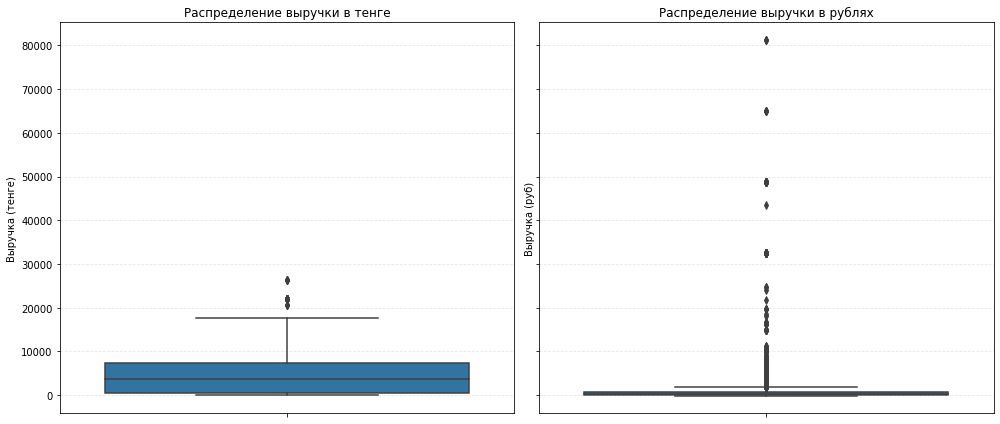

In [24]:
# Создаем графики
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# KZT
sns.boxplot(
    data=df_tickets[df_tickets['currency_code'] == 'kzt'],
    y='revenue',
    ax=axes[0],
    showfliers=True
)
axes[0].set_title('Распределение выручки в тенге')
axes[0].set_ylabel('Выручка (тенге)')
axes[0].grid(axis='y', linestyle='--', alpha=0.3)

# RUB
sns.boxplot(
    data=df_tickets[df_tickets['currency_code'] == 'rub'],
    y='revenue',
    ax=axes[1],
    showfliers=True
)
axes[1].set_title('Распределение выручки в рублях')
axes[1].set_ylabel('Выручка (руб)')
axes[1].grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

Для тенге и рублей наблюдаем среднее, что значительно выше медианы — признак правосторонней асимметрии распределения. То есть большинство заказов — в районе медианы, но есть «тяжёлый хвост» из крупных заказов или выбросов, которые тянут среднее вверх, это подтверждается максимальными значениями и видно на диаграммах размаха. Искажает среднее значение и минимальные значение (ноль для тенге и отрицательные для рублей). Так как у нас нет информации о статусе заказов и мы не можем понять причину таких значений - это были возвраты, отмены, промо-билеты или т.п. 

Теперь посмотрим статистические показатели для количества билетов в заказе `tickets_count`.

In [25]:
# Группируем по валюте и считаем базовые метрики
stats_by_tickets = df_tickets.groupby('currency_code')['tickets_count'].agg(
    total_tickets='sum',
    avg_tickets='mean',
    median_tickets='median',
    min_tickets='min',
    max_tickets='max',
    count_tickets='count',
    std_tickets='std'
).reset_index()

stats_by_tickets

,currency_code,total_tickets,avg_tickets,median_tickets,min_tickets,max_tickets,count_tickets,std_tickets
0,kzt,"14,005.00",2.76,3,1,6,5069,1.12
1,rub,"786,428.00",2.75,3,1,57,285542,1.17


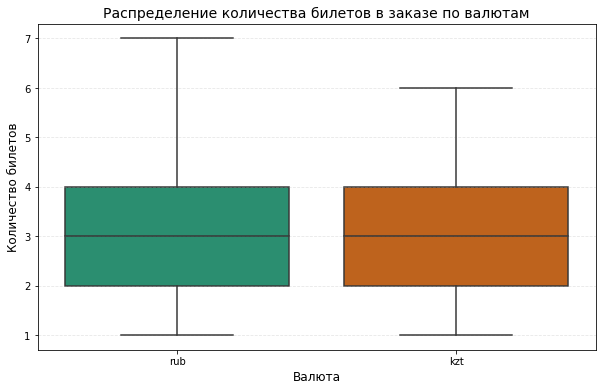

In [26]:
# Визуализируем Boxplot
plt.figure(figsize=(10, 6))
ax = sns.boxplot(
    data=df_tickets,
    x='currency_code',
    y='tickets_count',
    showfliers=False,
    palette='Dark2'        
)

# Подпись осей и заголовок
ax.set_title('Распределение количества билетов в заказе по валютам', fontsize=14)
ax.set_ylabel('Количество билетов', fontsize=12)
ax.set_xlabel('Валюта', fontsize=12)
ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.show()

* Типичный заказ очень похож в обеих валютах: медиана 3 билета и среднее около 2,75 — это устойчивая паттерн-поведение пользователей: чаще всего берут 2–3 билета.
* В рублях есть экстремальные заказы. Максимум 57 билетов против 6 в тенге — значит, в рублёвом сегменте есть специфические кейсы (корпоративные продажи, большие группы), которые могут искажать средние метрики. 
* Разброс небольшой. Стандартные отклонения ~1,1 говорят о том, что большинство заказов укладываются в 1–4 билета, а крупные заказы — это «хвост» распределения.

Для дальнейшего анализа мы отфильтруем данные, чтобы выручка была больше нуля и отберем значения по 99-му процентилю отдельно для каждой валюты для отсечения экстремальных выбросов.

In [27]:
# Считаем количество строк 
total_initial = len(df_tickets)

In [28]:
# Оставляем только положительные заказы
df_tickets = df_tickets[df_tickets['revenue'] > 0].copy()

In [29]:
# Считаем 99-й процентиль по каждой валюте и сразу получаем порог для каждой строки
p99_per_row = df_tickets.groupby('currency_code')['revenue'].transform(lambda s: s.quantile(0.99))

# Фильтруем
df_clean = df_tickets[df_tickets['revenue'] <= p99_per_row].copy()

# Смотрим пороги:
thresholds = df_tickets.groupby('currency_code')['revenue'].quantile(0.99)
print("Пороги 99-го процентиля по валютам:")
print(thresholds)

Пороги 99-го процентиля по валютам:
currency_code
kzt   17,617.24
rub    2,574.32
Name: revenue, dtype: float64


Визуализируем распределение значений выручки в рублях и тенге до и после фильтрации.

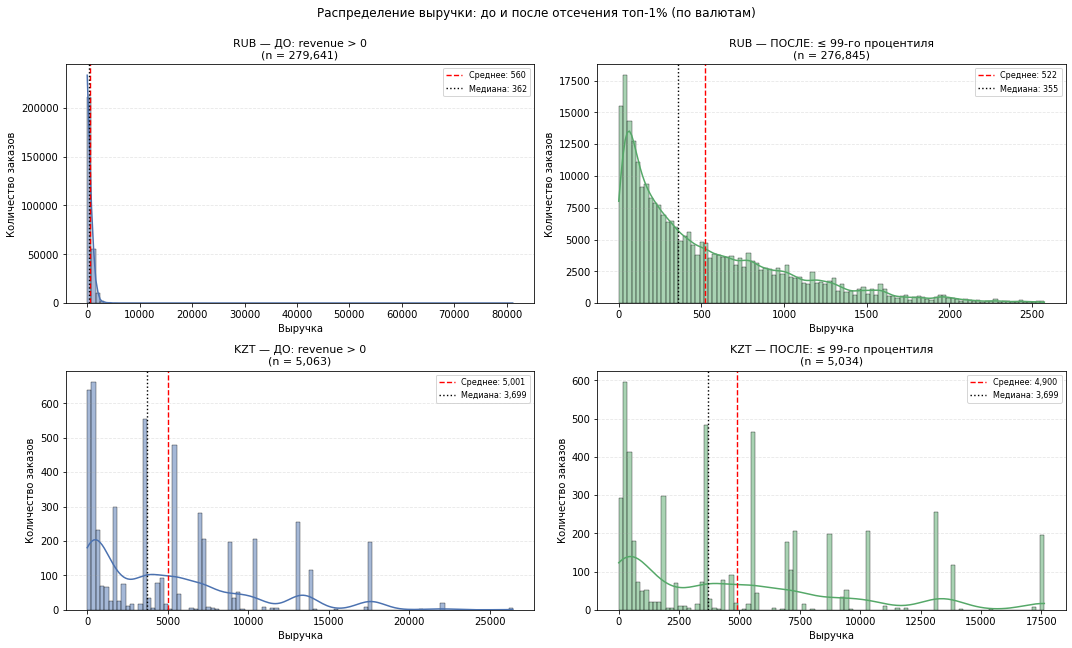

In [30]:
# Готовим срезы
frames = {
    'RUB': {
        'before': df_tickets[df_tickets['currency_code'] == 'rub'],
        'after':  df_clean[df_clean['currency_code'] == 'rub'],
    },
    'KZT': {
        'before': df_tickets[df_tickets['currency_code'] == 'kzt'],
        'after':  df_clean[df_clean['currency_code'] == 'kzt'],
    },
}

fig, axes = plt.subplots(2, 2, figsize=(15, 9))

for row, (curr, d) in enumerate(frames.items()):
    for col, stage in enumerate(['before', 'after']):
        ax = axes[row, col]
        data = d[stage]

        if len(data) == 0:
            ax.set_axis_off()
            continue

        sns.histplot(
            data=data, x='revenue', kde=True, bins=100, ax=ax,
            color='#4c72b0' if stage == 'before' else '#55a868'
        )
        ax.axvline(data['revenue'].mean(), color='red', linestyle='--',
                   linewidth=1.4, label=f'Среднее: {data["revenue"].mean():,.0f}')
        ax.axvline(data['revenue'].median(), color='black', linestyle=':',
                   linewidth=1.4, label=f'Медиана: {data["revenue"].median():,.0f}')

        title = 'ДО: revenue > 0' if stage == 'before' else 'ПОСЛЕ: ≤ 99-го процентиля'
        ax.set_title(f'{curr} — {title}\n(n = {len(data):,})', fontsize=11)
        ax.set_xlabel('Выручка')
        ax.set_ylabel('Количество заказов')
        ax.legend(fontsize=8)
        ax.grid(axis='y', linestyle='--', alpha=0.3)

fig.suptitle('Распределение выручки: до и после отсечения топ‑1% (по валютам)', y=0.995)
plt.tight_layout()
plt.show()

Зафиксируем статистику после фильтрации

In [31]:
# Считаем количество строк на каждом этапе
total_clean = len(df_clean)

# Количество отброшенных строк
dropped_count = total_initial - total_clean

# Процент отброшенных строк от исходного количества
dropped_percent = (dropped_count / total_initial) * 100

print(f"Было строк: {total_initial:}")
print(f"Стало строк (после фильтрации): {total_clean:}")
print(f"Отброшено строк: {dropped_count:}")
print(f"Процент отброшенных строк: {dropped_percent:.2f}%")

Было строк: 290611
Стало строк (после фильтрации): 281879
Отброшено строк: 8732
Процент отброшенных строк: 3.00%


---
<a id='2.5'></a>
### Явные и неявные дубликаты в данных
Начнём с полных дубликатов:

In [32]:
# Проверяем полные дубликаты в датафрейме 
df_clean.duplicated().sum()

0

В датафрейме нет полных дубликатов строк. Проверим неявные дубликаты без учёта идентификаторов заказа по "уникальным отпечаткам" бронирования - идентификаторы пользователя и события, время и выручка.

In [33]:
# Ищем дубли
mask_strict = df_clean.duplicated(subset=['user_id', 'event_id', 'created_ts_msk', 'revenue'], keep=False)

In [34]:
# Смотрим, что нашлось
duplicates_strict = df_clean[mask_strict].sort_values(['user_id', 'created_ts_msk'])

print(f"Строгих дублей (полное совпадение времени): {len(duplicates_strict)}")
display(duplicates_strict[['order_id', 'user_id', 'event_id', 'created_ts_msk', 'revenue', 'tickets_count']].head(20)) 

Строгих дублей (полное совпадение времени): 79


,order_id,user_id,event_id,created_ts_msk,revenue,tickets_count
11777,1123983,06eb7897f65b433,183706,2024-08-13 16:31:07,69.82,1
11778,1123867,06eb7897f65b433,183706,2024-08-13 16:31:07,69.82,1
26894,1930705,0dc525d7bacbb0d,393430,2024-07-31 13:26:11,"1,556.05",3
26896,1930763,0dc525d7bacbb0d,393430,2024-07-31 13:26:11,"1,556.05",3
51606,5378312,1f49b8de206b285,574431,2024-10-01 11:32:40,155.99,4
51647,2968673,1f49b8de206b285,574431,2024-10-01 11:32:40,155.99,4
53715,1935113,206ea45ec11d478,442183,2024-10-29 16:46:54,601.69,2
53717,1935171,206ea45ec11d478,442183,2024-10-29 16:46:54,601.69,2
57217,160922,2564e3703075008,589005,2024-10-30 10:04:15,11.23,2
57220,160893,2564e3703075008,589005,2024-10-30 10:04:15,11.23,2


Найдено 79 дублей, где задвоился заказ - строки полностью идентичны по всем полям кроме `order_id`. Удалим дубли, оставим одну строку на заказ.

In [35]:
# Оставляет первую найденную строку, остальные удаляет
df_clean = df_clean.drop_duplicates(subset=['user_id', 'event_id', 'created_ts_msk', 'revenue'], keep='first')

print(f"Было строк: {total_clean}")
print(f"Стало строк: {len(df_clean)}")
print(f"Удалено дублей: {total_clean - len(df_clean)}")

Было строк: 281879
Стало строк: 281838
Удалено дублей: 41


---
<a id='2.6'></a>
### Создание новых столбцов
Для удобства создадим следующие столбцы:
* `revenue_rub` — приведем выручку с заказа к единой валюте — российскому рублю. Для этого будем использовать датасет с информацией о курсе казахстанского тенге по отношению к российскому рублю `tickets_tenge` за 2024 год. Значения в рублях представлено для 100 тенге;
* `one_ticket_revenue_rub` — рассчитаем выручку с продажи одного билета на мероприятие;
* `month` — выделим месяц оформления заказа в отдельный столбец;
* `season` — создадим столбец с информацией о сезонности, включая такие категории, как: 'лето', 'осень', 'зима', 'весна'.

In [36]:
# Выделяем заказы в тенге
df_kzt = df_clean[df_clean['currency_code'] == 'kzt'].copy()

In [37]:
# Создаём ключ для объединения 
df_kzt['join_date'] = df_kzt['created_dt_msk'].dt.date
df_tenge['join_date'] = pd.to_datetime(df_tenge['data']).dt.date

In [38]:
# Присоединяем курс по дате
df_kzt_with_rate = df_kzt.merge(df_tenge[['join_date', 'curs']], on='join_date', how='left')

In [39]:
# Конвертация: revenue * (курс за 100 тенге / 100)
df_kzt_with_rate['revenue_rub'] = df_kzt_with_rate['revenue'] * (df_kzt_with_rate['curs'] / 100)

In [40]:
# Для рублей создадим аналогичную структуру, чтобы объединить их
df_rub = df_clean[df_clean['currency_code'] == 'rub'].copy()
df_rub['revenue_rub'] = df_rub['revenue']

# Объединяем части с конвертацией в одну маленькую таблицу: order_id + revenue_rub
df_revenue_map = pd.concat([
    df_kzt_with_rate[['order_id', 'revenue_rub']], 
    df_rub[['order_id', 'revenue_rub']]
], ignore_index=True)

# Объединяем с основым датафреймом
df = df_clean.merge(df_revenue_map, on='order_id', how='left')

# Проверка: нет ли пропусков в новой колонке?
if df['revenue_rub'].isna().any():
    print("⚠️ Ошибка: Для некоторых заказов не удалось рассчитать revenue_rub!")
else:
    print("✅ Конвертация прошла успешно! Все заказы имеют выручку в рублях.")

✅ Конвертация прошла успешно! Все заказы имеют выручку в рублях.


In [41]:
# check
df.loc[df['currency_code'] == 'kzt', ['total', 'revenue', 'revenue_rub', 'tickets_count']][:2]

,total,revenue,revenue_rub,tickets_count
65,"10,361.97",518.10,98.50,4
83,"6,943.61",347.18,65.73,3


In [42]:
# Расчёт выручки с одного билета 
df['one_ticket_revenue_rub'] = (
    df['revenue_rub'] / df['tickets_count']
)

In [43]:
# Выделяем месяц в отдельный столбец
df['month'] = df['created_dt_msk'].dt.month

In [44]:
# Создаем категорию сезонности
season_map = {
    12: 'зима', 1: 'зима', 2: 'зима',
    3: 'весна', 4: 'весна', 5: 'весна',
    6: 'лето', 7: 'лето', 8: 'лето',
    9: 'осень', 10: 'осень', 11: 'осень'
}

df['season'] = df['month'].map(season_map)

In [45]:
# Количество событий по сезону и месяцу
counts_by_season_month = (
    df.groupby(['season', 'month'], observed=True)
      .size()
      .reset_index(name='num_events')
)

counts_by_season_month

,season,month,num_events
0,лето,6,32900
1,лето,7,37882
2,лето,8,43166
3,осень,9,68891
4,осень,10,98999


---
***ВЫВОД:***
* Данные из двух датасетов были объединены в один датафрейм;
* Типы данных оптимизированы.
* Пропуски изучены. В `event_type_main` и `region_name` на `nan` поставлены заглушки "Тип не указан" и "Регион не определён".
* После изучения распределения выручки и количества билетов в заказе, данные были отфильтрованы по 99-му процентилю и оставлены только с положительной выручкой.
* Данные проверили на явные и неявные дубликаты — провели очистку от обнаруженных дубликатов.
* Во время предобработки было отброшено 3,09%. Осталось 281 838 строк.
* Были созданы новые столбцы: `revenue_rub` - выручка с единой валютой - рубль; `one_ticket_revenue_rub` — выручка с продажи одного билета; `month` — месяц оформления заказа; `season` — информацией о сезонности: 'лето', 'осень', 'зима', 'весна'.

[Назад к содержанию](#start)

---

## Исследовательский анализ данных
<a id='3.1'></a>
### Анализ распределения заказов по сегментам и их сезонные изменения

Изучим изменение пользовательской активности или пользовательского интереса в связи с сезонностью. 
Начнем с распределения количества заказов по месяцам.

In [46]:
# Группируем по месяцам и считаем количество заказов
orders_by_month = (
    df
    .groupby('month')['order_id']
    .nunique()
    .reset_index()
    .rename(columns={'order_id': 'orders_count'})
)

# Добавим названия месяцев 
month_names = {
    6: 'Июнь', 7: 'Июль', 8: 'Август', 9: 'Сентябрь', 10: 'Октябрь'
}

orders_by_month['month_name'] = orders_by_month['month'].map(month_names)

orders_by_month

,month,orders_count,month_name
0,6,32900,Июнь
1,7,37882,Июль
2,8,43166,Август
3,9,68891,Сентябрь
4,10,98999,Октябрь


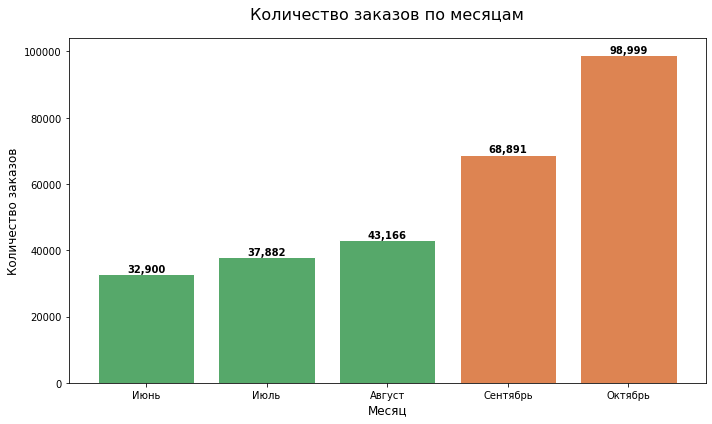

In [47]:
# Цвета по сезонам
orders_by_month['season'] = orders_by_month['month'].map(season_map)
season_colors = {
    'лето': '#56a86a',      
    'осень': '#dd8452'      
}
colors = orders_by_month['season'].map(season_colors)

# Создаем график
plt.figure(figsize=(10, 6))
bars = plt.bar(orders_by_month['month_name'], orders_by_month['orders_count'], color=colors, edgecolor='white', linewidth=1)

plt.title('Количество заказов по месяцам', fontsize=16, pad=20)
plt.xlabel('Месяц', fontsize=12)
plt.ylabel('Количество заказов', fontsize=12)

for bar in bars:
    height = bar.get_height()
    plt.annotate(f'{int(height):,}',
                 (bar.get_x() + bar.get_width() / 2., height),
                 ha='center', va='bottom', fontsize=10,  fontweight='bold')
    
plt.grid(False)
plt.tight_layout()
plt.show()

Наблюдаем устойчивый рост количества заказов на протяжении всего рассматриваемого периода. Особенно существенный прирост фиксируется в сентябре и октябре: в сентябре показатель вырос на 59,6 % по сравнению с августом, а в октябре — на 43,7 % относительно сентября. Такая динамика может свидетельствовать о сезонном всплеске спроса.

---

Сравним распределение заказов билетов по разным категориям: 
* тип мероприятия;
* тип устройства;
* категория мероприятия по возрастному рейтингу. 

In [48]:
# Функция для расчета долей и построения графика
def plot_season_shares(
    df, 
    category_col, 
    season_month_count={'лето': 3, 'осень': 2}, 
    ascending=False, 
    sort_by=None,
    figsize=(10, 6),
    xlim_max=100
):
    
    # Справочник для красивых названий в заголовке
    label_map = {
        'event_type_main': 'типу мероприятий',
        'device_type_canonical': 'типу устройств',
        'age_limit': 'возрастному рейтингу'
    }
    display_name = label_map.get(category_col, category_col)
    
    # Считаем количество заказов по категории и сезону
    sums = (
        df
        .groupby([category_col, 'season'])['order_id']
        .nunique()
        .reset_index()
        .rename(columns={'order_id': 'orders_count'})
    )

    # Добавляем число месяцев в сезоне и считаем среднемесячные значения
    sums['months_in_season'] = sums['season'].map(season_month_count)
    sums['avg_monthly_orders'] = sums['orders_count'] / sums['months_in_season']

    # Считаем суммарный среднемесячный объём по сезону 
    season_totals = (
        sums
        .groupby('season')['avg_monthly_orders']
        .sum()
        .reset_index()
        .rename(columns={'avg_monthly_orders': 'season_total_avg'})
    )

    sums = sums.merge(season_totals, on='season')
    sums['share_pct'] = sums['avg_monthly_orders'] / sums['season_total_avg'] * 100
    
     # Сводные таблицы
    pivot_share = (
        sums
        .pivot(index=category_col, columns='season', values='share_pct')
        .fillna(0)
    )
    
    pivot_avg = (
        sums
        .pivot(index=category_col, columns='season', values='avg_monthly_orders')
        .fillna(0)
        .astype(int)
    )
    
    if sort_by is None:
        sort_by = 'лето'
        
    pivot_share = pivot_share.sort_values(by=sort_by, ascending=ascending)
    pivot_avg = pivot_avg.loc[pivot_share.index]

    # Построение графика
    x = range(len(pivot_share))
    width = 0.35

    fig, ax = plt.subplots(figsize=figsize)

    bars1 = ax.barh([i + width/2 for i in x], pivot_share['лето'], width, label='Лето', color='#56a86a')
    bars2 = ax.barh([i - width/2 for i in x], pivot_share['осень'], width, label='Осень', color='#dd8452')

    ax.set_yticks(x)
    ax.set_yticklabels(pivot_share.index)
    ax.set_title(f'Доля заказов по {display_name}:\nЛето vs Осень')
    ax.set_xlabel('Доля заказов (%)')
    ax.set_xlim(0, xlim_max)
    ax.grid(axis='x', linestyle='--', alpha=0.3)
    ax.legend(loc='lower right')

    # Подписи снаружи
    for bar in bars1:
        w = bar.get_width()
        ax.text(w + 1, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center', fontsize=9, fontweight='bold')
    for bar in bars2:
        w = bar.get_width()
        ax.text(w + 1, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center', fontsize=9, fontweight='bold')

    plt.tight_layout()
    plt.show()
    
    return pivot_avg

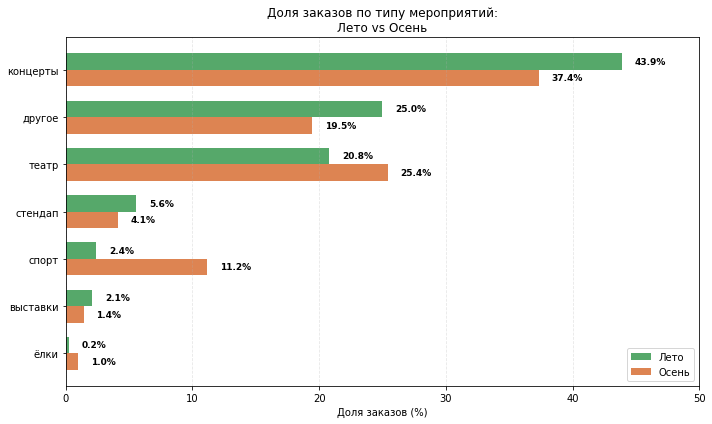

season,лето,осень
event_type_main,,
ёлки,91,846
выставки,802,1201
спорт,920,9388
стендап,2115,3461
театр,7899,21353
другое,9492,16333
концерты,16661,31361


In [49]:
# Вызываем функцию по типу мероприятий
plot_season_shares(df, 'event_type_main', sort_by='лето', ascending=True, xlim_max=50)

* Концерты доминируют в обоих сезонах: среднемесячно 16 661 заказ летом и 31 361 — осенью. Абсолютный рост почти в 2 раза говорит о том, что снижение доли (с 43,9 % до 37,4 %) — это не про падение интереса, а про то, что другие категории растут ещё быстрее.
* Театр демонстрирует рост доли — с 20,8 % летом до 25,4 % осенью (рост с 7 899 до 21 353 заказов в среднем за месяц — это более чем 2,7‑кратный прирост). Вероятно, с началом осеннего сезона активизируется театральная афиша и растёт интерес аудитории к этому формату досуга.
* В категории «другое» объем заказов растёт с 9 492 до 16 333, при этом доля снижается с 25,0 % до 19,5 %, потому что ещё сильнее выросли театр и спорт. Категория «другое» остаётся одной из самых объёмных и стабильно растущих.
* Спорт показывает выраженный рост доли — с 2,4 % летом до 11,2 % осенью (с 920 до 9 388 заказов в среднем за месяц - более чем в 10 раз). Это может быть обусловлено стартом осенних спортивных сезонов, увеличением числа матчей или турниров, а также 
* Стендап — заказы увеличиваются с 2 115 до 3 461, то есть категория уверенно растёт, но доля в разрезе всех мероприятий незначительно снижается (с 5,6 % до 4,1 %).
* У выставок также наблюдается устойчивая положительная динамика: рост с 802 до 1 201 заказа в среднем за месяц. Даже при снижении доли (с 2,1 % до 1,4 %) это говорит о реальном увеличении спроса, а не о его перераспределении.
* Ёлки имеют минимальную долю, так как пик спроса на этот тип мероприятий приходится на более поздние месяцы (декабрь–январь).

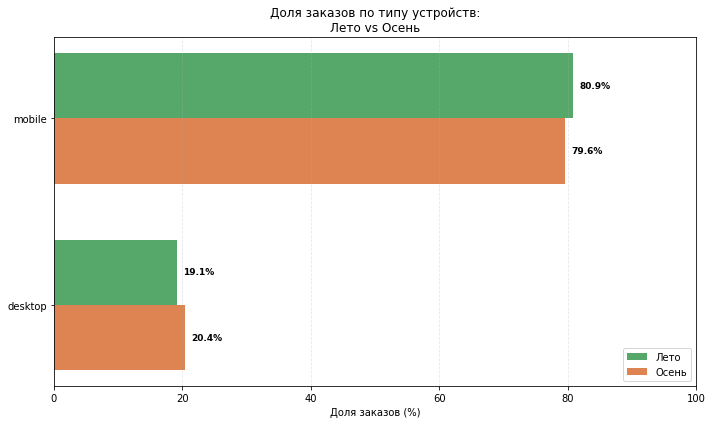

season,лето,осень
device_type_canonical,,
desktop,7259,17120
mobile,30723,66824


In [50]:
# Вызываем функцию по типу устройств
plot_season_shares(df, 'device_type_canonical', sort_by='лето', ascending=True)

* Mobile‑устройства стабильно доминируют в обоих сезонах:  их среднемесячный объём — 30 728 заказов летом и 66 828 заказов осенью. При этом на их долю приходится 80,9 % заказов летом и 79,6 % — осенью. Это говорит о высокой востребованности мобильной версии сервиса или мобильного приложения среди пользователей.
* Доля desktop‑заказов незначительно растёт осенью — с 19,1 % летом до 20,4 % осенью (с 7 260 до 17 121 заказов в месяц). Рост на 1,3 п. п. может быть связан с возвращением части аудитории к рабочим местам после летнего периода, увеличением офисной активности или изменением привычек пользователей в холодное время года.
* Общая структура почти не меняется: несмотря на небольшой сдвиг, соотношение mobile/desktop остаётся примерно на уровне 4:1, что свидетельствует о сформировавшемся устойчивом паттерне поведения пользователей.

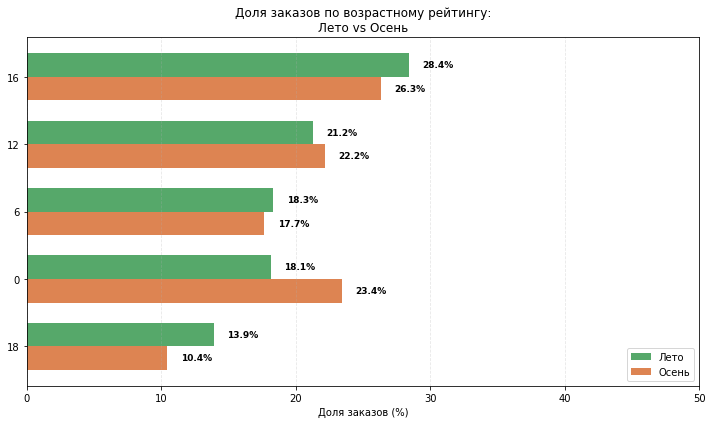

season,лето,осень
age_limit,,
18,5271,8769
0,6886,19642
6,6960,14820
12,8068,18612
16,10796,22101


In [51]:
# Вызываем функцию по возрастному рейтингу
plot_season_shares(df, 'age_limit', sort_by='лето', ascending=True, xlim_max=50)

* Рейтинг «16+» остаётся лидером в оба сезона 10 797 заказов летом и 22 101 осенью, хотя его доля немного снижается осенью — с 28,4 % летом до 26,3 % осенью. Это говорит о стабильно высокой востребованности контента для подростков и молодёжи, но относительное «ослабление» доли отражает перераспределение спроса в пользу других возрастных групп.
* Доля рейтинга «18+» заметно падает осенью — с 13,9 % летом до 10,4 %, при этом абсолютный среднемесячный объём заказов растёт (с 5 271 до 8 769). Возможно, это связано с изменением репертуара мероприятий, смещением спроса на семейный контент или сезонными особенностями аудитории.
* Рейтинг «0+» демонстрирует самый сильный рост: среднемесячные заказы увеличиваются с 6 886 до 19 642, а доля — с 18,1 % до 23,4 %. Такой существенный прирост может отражать рост спроса на семейный и детский досуг с началом учебного года либо расширение предложения в этом сегменте.
* Рейтинг «12+» также растёт — среднемесячный объём увеличивается с 8 071 до 18 614, доля с 21,2 % летом до 22,2 % осенью, что согласуется с общей тенденцией к увеличению доли «семейного» и «подросткового» контента.
* Рейтинг «6+» показывает небольшое снижение — с 18,3 % летом до 17,7 % осенью, хотя абсолютный среднемесячный объём растёт (с 6 962 до 14 823). Падение незначительное, но оно вписывается в общую картину перераспределения спроса в пользу более «старших» возрастных категорий внутри семейного сегмента.

---

Изучим динамику средней выручки с заказа билета в разрезе разных категорий мероприятий летом и осенью.

In [52]:
# Считаем среднюю выручку с одного билета по типу мероприятия и сезону
revenue_by_season = (
    df
    .groupby(['event_type_main', 'season'])['one_ticket_revenue_rub']
    .mean()
    .unstack(fill_value=0)
)

In [53]:
# Считаем относительное изменение (осень vs лето) в процентах
revenue_change_pct = (
    (revenue_by_season['осень'] - revenue_by_season['лето']) 
    / revenue_by_season['лето'] 
    * 100
).dropna()

In [54]:
# Формируем итоговый датафрейм
revenue_summary = revenue_by_season.copy()
revenue_summary['change_pct'] = revenue_change_pct
revenue_summary = revenue_summary.sort_values(by='change_pct', ascending=False) 

revenue_summary

season,лето,осень,change_pct
event_type_main,,,
выставки,86.74,91.91,5.95
стендап,218.52,231.12,5.77
спорт,55.25,50.25,-9.05
другое,88.02,77.42,-12.04
концерты,309.56,268.43,-13.28
ёлки,271.44,229.96,-15.28
театр,216.35,176.08,-18.61


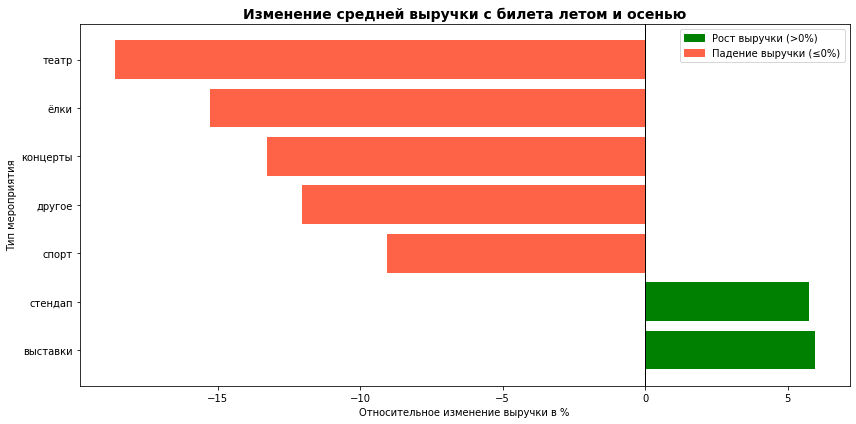

In [55]:
# Создаем график
fig, ax = plt.subplots(figsize=(12, 6))

# Подготавливаем данные
types = revenue_summary.index
changes = revenue_summary['change_pct']

# Цвета: зелёный — рост, красный — падение
colors = ['green' if x > 0 else 'tomato' for x in changes]

# Построение горизонтальных столбцов
bars = ax.barh(types, changes, color=colors)

# Настройка осей и заголовка 
ax.set_xlabel('Относительное изменение выручки в %')
ax.set_ylabel('Тип мероприятия')
ax.set_title('Изменение средней выручки с билета летом и осенью', weight='bold', fontsize=14)
ax.axvline(0, color='black', linewidth=1)  # Линия нуля

# Легенда 
ax.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color='green'),
        plt.Rectangle((0, 0), 1, 1, color='tomato')
    ],
    labels=['Рост выручки (>0%)', 'Падение выручки (≤0%)'],
    loc='upper right'
)

plt.tight_layout()
plt.show()

* По всем типам мероприятий средняя выручка с билета летом превышает осеннюю, за исключением категории «стендап» (219 руб. летом vs 231 руб. осенью).
* Наибольшая выручка фиксируется в сегменте «концерты»: 310 руб. летом и 268 руб. осенью.
* Наименьшая выручка — в категории «спорт»: 55 руб. летом и 50 руб. осенью.
* Наиболее выраженный спад выручки осенью наблюдается в сегментах «ёлки» (с 271 до 230 руб., −15,1 %) и «концерты» (с 310 до 268 руб., −13,5 %).
* Устойчиво высокий уровень выручки (свыше 200 руб.) характерен для категорий «театр», «стендап», «ёлки» и «концерты» как в летний, так и в осенний периоды.

[Назад к содержанию](#start)

---

<a id='3.2'></a>
### Осенняя активность пользователей
Проанализируем динамику изменений по дням в осенние месяцы для: 
* общего числа заказов;
* количества активных пользователей DAU;
* среднего числа заказов на одного пользователя;
* средней стоимости одного билета.

In [56]:
# Извлекаем дату 
df['date'] = df['created_dt_msk'].dt.date

In [57]:
# Фильтруем осенние месяцы
start_date = pd.Timestamp('2024-09-01')
end_date = pd.Timestamp('2024-10-31 23:59:59')

mask = (df['date'] >= start_date) & (df['date'] <= end_date)
df_autumn = df[mask].copy()

In [58]:
# Группировка по дате для расчёта метрик
daily_metrics = (
    df_autumn.groupby(df_autumn['date'])
    .agg(
        total_orders=('order_id', 'nunique'),
        dau=('user_id', 'nunique'),
        avg_ticket_price=('one_ticket_revenue_rub', 'mean')
    )
    .reset_index()
)

In [59]:
# Расчёт среднего числа заказов на одного пользователя
daily_metrics['orders_per_user'] = daily_metrics['total_orders'] / daily_metrics['dau']

# Вывод сводной таблицы
daily_metrics[['date', 'total_orders', 'dau', 'orders_per_user', 'avg_ticket_price']].round(2)

,date,total_orders,dau,orders_per_user,avg_ticket_price
0,2024-09-01,1314,555,2.37,202.15
1,2024-09-02,1370,571,2.40,190.85
2,2024-09-03,5090,776,6.56,80.71
3,2024-09-04,1758,684,2.57,179.57
4,2024-09-05,1940,738,2.63,189.90
...,...,...,...,...,...
56,2024-10-27,2841,1031,2.76,187.50
57,2024-10-28,2837,985,2.88,170.94
58,2024-10-29,2831,998,2.84,177.62
59,2024-10-30,2924,1039,2.81,182.98


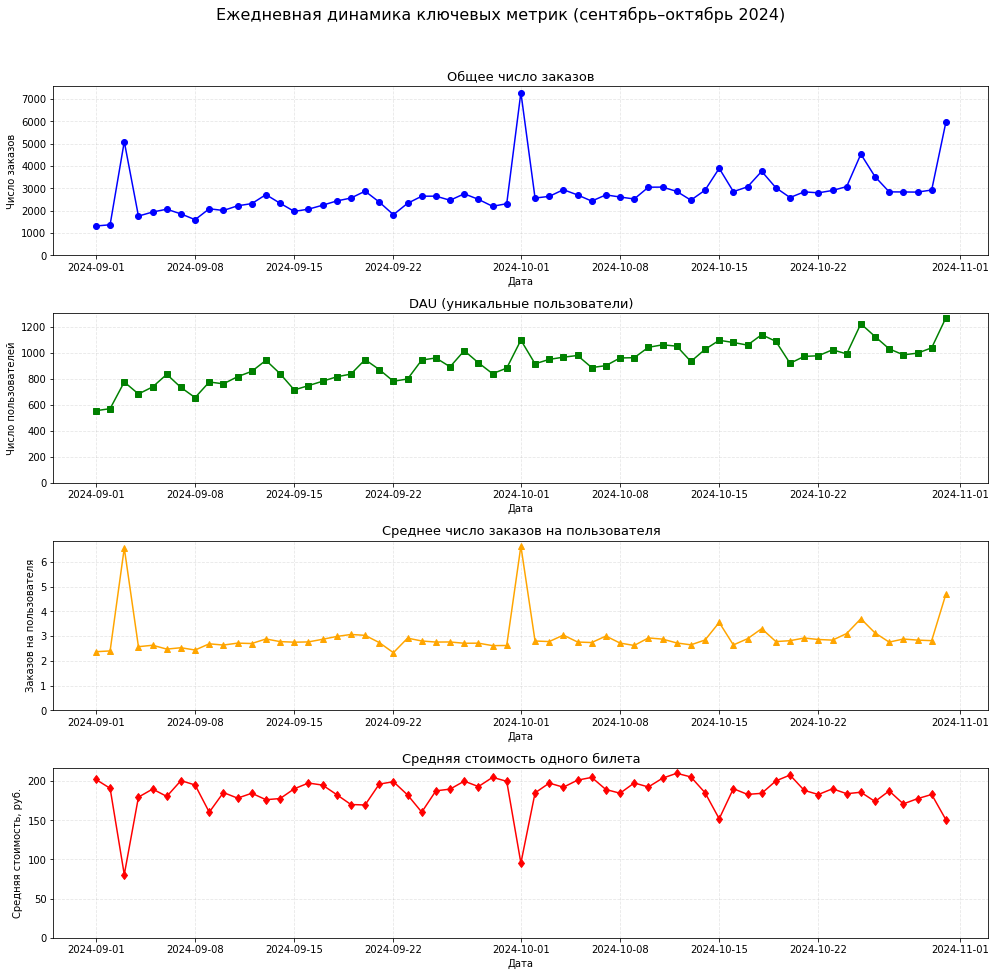

In [60]:
# Строим 4 графика
fig, axes = plt.subplots(4, 1, figsize=(14, 14))  

# 1. Общее число заказов
axes[0].plot(daily_metrics['date'], daily_metrics['total_orders'], marker='o', color='blue')
axes[0].set_title('Общее число заказов', fontsize=13)
axes[0].set_ylabel('Число заказов')
axes[0].set_xlabel('Дата')
axes[0].grid(True, linestyle='--', alpha=0.3)
axes[0].set_ylim(bottom=0)

# 2. DAU
axes[1].plot(daily_metrics['date'], daily_metrics['dau'], marker='s', color='green')
axes[1].set_title('DAU (уникальные пользователи)', fontsize=13)
axes[1].set_ylabel('Число пользователей')
axes[1].set_xlabel('Дата')
axes[1].grid(True, linestyle='--', alpha=0.3)
axes[1].set_ylim(bottom=0)

# 3. Заказов на пользователя
axes[2].plot(daily_metrics['date'], daily_metrics['orders_per_user'], marker='^', color='orange')
axes[2].set_title('Среднее число заказов на пользователя', fontsize=13)
axes[2].set_ylabel('Заказов на пользователя')
axes[2].set_xlabel('Дата')
axes[2].grid(True, linestyle='--', alpha=0.3)
axes[2].set_ylim(bottom=0)

# 4. Средняя стоимость билета
axes[3].plot(daily_metrics['date'], daily_metrics['avg_ticket_price'], marker='d', color='red')
axes[3].set_title('Средняя стоимость одного билета', fontsize=13)
axes[3].set_xlabel('Дата')
axes[3].set_ylabel('Средняя стоимость, руб.')
axes[3].set_xlabel('Дата')
axes[3].grid(True, linestyle='--', alpha=0.3)
axes[3].set_ylim(bottom=0)

plt.suptitle('Ежедневная динамика ключевых метрик (сентябрь–октябрь 2024)', fontsize=16, y=0.995)
plt.tight_layout(rect=[0, 0.03, 1, 0.97]) 
plt.show()

По графику видим выбросы 03.09, 01.10 и 31.10, посмотрим детальнее на эти дни, чтобы найти источники таких всплесков.

In [61]:
def analyze_daily_sales(df, target_date):
    # Фильтрация по дате
    date_obj = pd.Timestamp(target_date).date()
    daily_df = df[df['date'] == date_obj].copy()

    if daily_df.empty:
        return None, None
    
    # Группировка по мероприятиям
    events_df = daily_df.groupby('event_id').agg(
        total_orders=('order_id', 'count'),
        avg_price=('one_ticket_revenue_rub', 'mean'),
        median_price=('one_ticket_revenue_rub', 'median'),
        total_revenue=('revenue_rub', 'sum'),
        service_name=('service_name', 'first'),      
        venue_name=('venue_name', 'first'),     
        event_type=('event_type_main', 'first'),
        city=('city_name', 'first'),
        region=('region_name', 'first')
    ).reset_index()
    
    events_df = events_df.sort_values(by='total_orders', ascending=False)
    
    print("\nТоп-15 мероприятий по количеству заказов:")
    display(events_df.head(15))
    
    return events_df, daily_df

In [62]:
dates_to_check = ['2024-09-03', '2024-10-01', '2024-10-31']

results = {}
for d in dates_to_check:
    print(f"--- Обработка даты: {d} ---")
    events_top, day_metrics = analyze_daily_sales(df_autumn, d)

--- Обработка даты: 2024-09-03 ---

Топ-15 мероприятий по количеству заказов:


,event_id,total_orders,avg_price,median_price,total_revenue,service_name,venue_name,event_type,city,region
750,564990,780,38.93,38.93,"89,577.93",Билеты в руки,"Студия дизайна ""Платформа"" Инкорпорэйтед",спорт,Радужсвет,Медовская область
749,564987,770,16.41,16.41,"41,225.11",Билеты в руки,"Студия дизайна ""Платформа"" Инкорпорэйтед",спорт,Радужсвет,Медовская область
736,563901,633,34.36,34.36,"67,545.20",Билеты в руки,"Студия дизайна ""Платформа"" Инкорпорэйтед",спорт,Радужсвет,Медовская область
751,564991,422,35.38,35.38,"46,843.12",Билеты в руки,"Студия дизайна ""Платформа"" Инкорпорэйтед",спорт,Радужсвет,Медовская область
276,428762,304,67.98,67.98,"63,633.24",Билеты в руки,"Студия дизайна ""Платформа"" Инкорпорэйтед",спорт,Радужсвет,Медовская область
401,501912,295,52.84,52.84,"48,452.44",Билеты в руки,"Студия дизайна ""Платформа"" Инкорпорэйтед",спорт,Радужсвет,Медовская область
298,440309,218,47.68,47.67,"32,705.55",Билеты в руки,"Студия дизайна ""Платформа"" Инкорпорэйтед",спорт,Радужсвет,Медовская область
297,440264,121,52.63,52.63,"21,157.11",Билеты в руки,"Студия дизайна ""Платформа"" Инкорпорэйтед",спорт,Радужсвет,Медовская область
681,559476,37,21.63,21.63,"2,249.06",Билеты без проблем,"Клуб настольного тенниса ""Фазенда"" Инк",другое,Серебрянка,Верхоречная область
686,559769,31,3.67,3.67,293.54,Билеты без проблем,"Театральные мастерские ""Лавровый"" Инк",другое,Лесореченск,Широковская область


--- Обработка даты: 2024-10-01 ---

Топ-15 мероприятий по количеству заказов:


,event_id,total_orders,avg_price,median_price,total_revenue,service_name,venue_name,event_type,city,region
1098,574431,1475,39.00,39.00,"176,655.96",Билеты в руки,"Студия дизайна ""Платформа"" Инкорпорэйтед",спорт,Радужсвет,Медовская область
1100,574450,878,17.95,17.95,"48,288.70",Билеты в руки,"Студия дизайна ""Платформа"" Инкорпорэйтед",спорт,Радужсвет,Медовская область
492,457197,533,48.06,48.06,"85,889.22",Билеты в руки,"Студия дизайна ""Платформа"" Инкорпорэйтед",спорт,Радужсвет,Медовская область
516,470263,404,54.38,54.38,"64,385.92",Билеты в руки,"Студия дизайна ""Платформа"" Инкорпорэйтед",спорт,Радужсвет,Медовская область
1097,574410,337,30.17,30.17,"34,482.82",Билеты в руки,"Студия дизайна ""Платформа"" Инкорпорэйтед",спорт,Радужсвет,Медовская область
1099,574441,314,30.61,30.61,"31,986.96",Билеты в руки,"Студия дизайна ""Платформа"" Инкорпорэйтед",спорт,Радужсвет,Медовская область
1096,574407,185,21.12,21.12,"13,350.59",Билеты в руки,"Студия дизайна ""Платформа"" Инкорпорэйтед",спорт,Радужсвет,Медовская область
1101,574456,153,29.81,29.82,"14,817.68",Билеты в руки,"Студия дизайна ""Платформа"" Инкорпорэйтед",спорт,Радужсвет,Медовская область
415,428761,122,58.12,58.12,"21,678.76",Билеты в руки,"Студия дизайна ""Платформа"" Инкорпорэйтед",спорт,Радужсвет,Медовская область
414,428759,105,85.17,85.17,"29,981.11",Билеты в руки,"Студия дизайна ""Платформа"" Инкорпорэйтед",спорт,Радужсвет,Медовская область


--- Обработка даты: 2024-10-31 ---

Топ-15 мероприятий по количеству заказов:


,event_id,total_orders,avg_price,median_price,total_revenue,service_name,venue_name,event_type,city,region
1328,589623,1027,80.62,80.62,"190,182.58",Мой билет,"Картинная галерея ""Светлячок"" Лтд",концерты,Глиногорск,Каменевский регион
1329,589624,949,41.83,41.83,"93,657.37",Мой билет,"Картинная галерея ""Светлячок"" Лтд",концерты,Глиногорск,Каменевский регион
1332,589957,604,298.76,298.76,"414,080.66",Мой билет,"Картинная галерея ""Светлячок"" Лтд",концерты,Глиногорск,Каменевский регион
1331,589837,199,94.61,94.61,"38,979.24",Мой билет,"Музей науки ""Спелка"" Инкорпорэйтед",концерты,Озёрск,Североярская область
1333,589958,54,192.91,192.91,"20,062.29",Мой билет,"Музей науки ""Спелка"" Инкорпорэйтед",концерты,Озёрск,Североярская область
1086,574456,45,29.81,29.81,"3,100.64",Билеты в руки,"Студия дизайна ""Платформа"" Инкорпорэйтед",спорт,Радужсвет,Медовская область
572,459673,29,492.58,492.58,"43,346.76",Весь в билетах,"Клуб настольных игр ""Canvas"" Инкорпорэйтед",концерты,Светополье,Яблоневская область
1136,578055,28,17.10,17.10,"1,368.00",Радио ticket,"Арт-фестиваль ""Таблицы"" Лтд",другое,Глиногорск,Каменевский регион
671,509453,24,463.47,463.47,"28,271.62",Билеты без проблем,"Театр кукол ""Огни"" Инкорпорэйтед",стендап,Родниковецк,Озернинский край
697,521167,23,62.56,62.56,"4,191.67",Лови билет!,"Народный ансамбль ""Дизайн"" Инкорпорэйтед",выставки,Глиногорск,Каменевский регион


Во всех датах с всплесками по количеству заказов наблюдаем следующее: одно и тоже мероприятие, проводимое в один и тот же день на одной и той же площадке имеет разные `event_id`, что безусловное является ошибкой в данных. Это спортивные мероприятия и если в дальнейшем необходимо будет проводить стат тесты, необходимо, проверять гипотезы без спортивных мероприятий, т.к. они дают огромные всплески.

* Общее число заказов демонстрирует волатильность с резкими пиками (например, в начале сентября и начале октября), далее — относительно стабильный уровень с локальными всплесками; к концу периода наблюдается рост.
* DAU показывает устойчивый тренд на увеличение: от ~600 в начале сентября до ~1300 к началу ноября, с умеренной волатильностью внутри периода.
* Среднее число заказов на пользователя характеризуется высокой изменчивостью и выраженными выбросами (до ~6–7 заказов), при этом базовый уровень держится в диапазоне 2–3 заказов; к концу периода показатель растет.
* Средняя стоимость билета колеблется в диапазоне 140–200 руб., с резкими провалами (до ~100 руб.) в отдельные дни; общий тренд — умеренная волатильность без выраженного роста или падения.

---

Изучим недельную цикличность: сравним пользовательскую активность в будни и выходные.

In [63]:
# Добавляем признак «день недели» (0=понедельник, 6=воскресенье)
df_autumn['day_of_week'] = df_autumn['date'].apply(lambda x: x.weekday())

In [64]:
# Создаём признак «тип дня»: будни/выходные
# 0–4 — будни, 5–6 — выходные
df_autumn['day_type'] = df_autumn['day_of_week'].apply(
    lambda x: 'выходные' if x >= 5 else 'будни'
)

In [65]:
# Группируем по типу дня и считаем метрики
weekday_metrics = (
    df_autumn.groupby('day_type')
    .agg(
        total_orders=('order_id', 'nunique'),
        dau=('user_id', 'nunique'),
        avg_ticket_price=('one_ticket_revenue_rub', 'mean'),
    )
    .reset_index()
)

In [66]:
# Считаем среднее число заказов на пользователя
weekday_metrics['orders_per_user'] = weekday_metrics['total_orders'] / weekday_metrics['dau']

In [67]:
# Выводим результат
weekday_metrics[['day_type', 'total_orders', 'dau', 'orders_per_user', 'avg_ticket_price']].round(2)

,day_type,total_orders,dau,orders_per_user,avg_ticket_price
0,будни,127470,13187,9.67,173.35
1,выходные,40420,7080,5.71,196.51


In [68]:
# Метрики по каждому дню недели
daily_week_metrics = (
    df_autumn.groupby('day_of_week', observed=True)
    .agg(
        total_orders=('order_id', 'nunique'),
        dau=('user_id', 'nunique'),
        avg_ticket_price=('one_ticket_revenue_rub', 'mean'),
    )
    .reset_index()
)

In [69]:
# Среднее число заказов на пользователя
daily_week_metrics['orders_per_user'] = daily_week_metrics['total_orders'] / daily_week_metrics['dau']

In [70]:
# Добавим название дня для читаемости
day_names = {
    0: 'Пн', 1: 'Вт', 2: 'Ср', 3: 'Чт', 4: 'Пт', 5: 'Сб', 6: 'Вс'
}
daily_week_metrics['day_name'] = daily_week_metrics['day_of_week'].map(day_names)

In [71]:
# Переупорядочим по дням недели и округлим
daily_week_metrics = daily_week_metrics.sort_values('day_of_week')
cols_to_show = ['day_name', 'total_orders', 'dau', 'orders_per_user', 'avg_ticket_price']

daily_week_metrics[cols_to_show].round(2)

,day_name,total_orders,dau,orders_per_user,avg_ticket_price
0,Пн,21467,4434,4.84,184.64
1,Вт,31411,4785,6.56,141.00
2,Ср,22830,4810,4.75,186.47
3,Чт,27068,4961,5.46,178.57
4,Пт,24694,4844,5.10,186.80
5,Сб,21195,4527,4.68,193.62
6,Вс,19225,4345,4.42,199.71


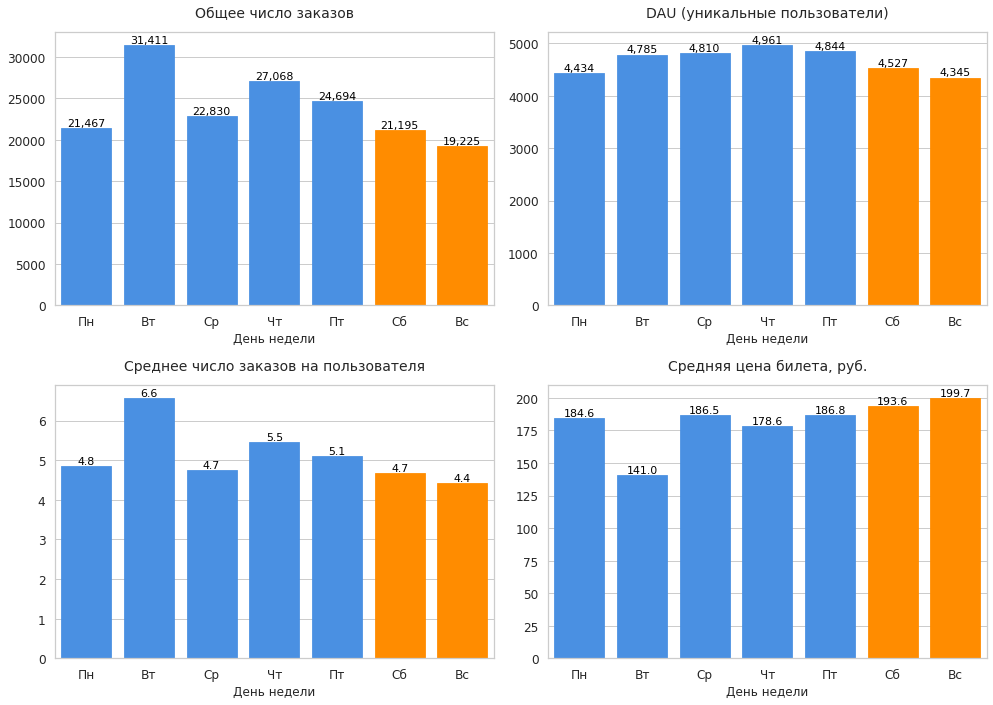

In [72]:
# Настройка стиля
sns.set(style="whitegrid", font_scale=1.1)

data = daily_week_metrics.copy()

# Создаем фигуру 
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

metrics = [
    ('total_orders', 'Общее число заказов'),
    ('dau', 'DAU (уникальные пользователи)'),
    ('orders_per_user', 'Среднее число заказов на пользователя'),
    ('avg_ticket_price', 'Средняя цена билета, руб.')
]

# Порядок дней для корректного отображения
day_order = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']

# Задаем цвет
color_weekday = '#4A90E2'
color_weekend = '#FF8C00'

for i, (col, title) in enumerate(metrics):
    ax = axes[i]
    
    # Строим barplot
    sns.barplot(
        data=data,
        x='day_name',
        y=col,
        ax=ax,
        order=day_order,
        edgecolor='black',
        linewidth=0.8
    )
    
    ax.set_title(title, fontsize=14, pad=15)
    ax.set_xlabel('День недели', fontsize=12)
    ax.set_ylabel('')
    
    # Раскрашиваем столбцы: будни и выходные
    for j, patch in enumerate(ax.patches):
        day_name = data['day_name'].iloc[j] if j < len(data) else ''
        if day_name in ['Сб', 'Вс']:
            patch.set_color(color_weekend)
        else:
            patch.set_color(color_weekday)
    
    # Подписи значений на столбцах
    for p in ax.patches:
        height = p.get_height()
        if col in ['total_orders', 'dau']:
            label = f'{int(height):,}'
        else:
            label = f'{height:.1f}'
        ax.annotate(
            label,
            (p.get_x() + p.get_width() / 2., height),
            ha='center',
            va='bottom',
            fontsize=11,
            color='black'
        )

plt.tight_layout()
plt.show()

* В будни объём заказов существенно выше: 127 478 против 40 421 в выходные;
* DAU в будни почти вдвое больше (13 188 против 7 080), что подтверждает более высокую пользовательскую активность в рабочие дни;
* При этом в будни выше и интенсивность использования сервиса: в среднем 9,67 заказа на пользователя против 5,71 в выходные;
* Средний чек в выходные заметно выше — 197 руб. против 173 руб. в будни, вероятно, из‑за иной структуры спроса или ценовой политики в эти дни.
* Аномалия вторника: крайне низкая средняя цена билета (141 руб.) при максимальном числе заказов и высокой частоте покупок. 

[Назад к содержанию](#start)

---

<a id='3.3'></a>
### Популярные события и партнёры
Посмотрим, как события распределены по регионам и партнёрам, тем самым выделим ключевые регионы и партнёров, которые вносят наибольший вклад в выручку.

In [73]:
# Анализ по регионам
region_agg = (
    df
    .groupby('region_name', as_index=False)
    .agg(
        unique_events=('event_id', 'nunique'),
        total_orders=('order_id', 'count')
    )
)

In [74]:
# Считаем доли
total_events = region_agg['unique_events'].sum()
total_orders = region_agg['total_orders'].sum()

region_agg['events_share_%'] = (region_agg['unique_events'] / total_events * 100).round(2)
region_agg['orders_share_%'] = (region_agg['total_orders'] / total_orders * 100).round(2)

In [75]:
# Сортируем по разнообразию мероприятий 
region_result = region_agg.sort_values('unique_events', ascending=False).reset_index(drop=True)

region_result

,region_name,unique_events,total_orders,events_share_%,orders_share_%
0,Каменевский регион,5793,85397,26.32,30.30
1,Североярская область,3777,43590,17.16,15.47
2,Широковская область,1217,16087,5.53,5.71
3,Светополянский округ,1059,7463,4.81,2.65
4,Речиновская область,701,6265,3.19,2.22
...,...,...,...,...,...
76,Теплоозёрский округ,2,7,0.01,0.00
77,Сосноводолинская область,2,10,0.01,0.00
78,Лесноярский край,2,19,0.01,0.01
79,Светолесский край,2,24,0.01,0.01


In [76]:
# Топ-3 по мероприятиям
top3_events = region_agg.nlargest(3, 'unique_events')
other_events_sum = region_agg['unique_events'].sum() - top3_events['unique_events'].sum()

# Топ-3 по заказам
top3_orders = region_agg.nlargest(3, 'total_orders')
other_orders_sum = region_agg['total_orders'].sum() - top3_orders['total_orders'].sum()

# Данные для диаграмм
# ---------------------------------------------------------
# По мероприятиям
labels_events = list(top3_events['region_name']) + ['Остальные регионы']
values_events = list(top3_events['unique_events']) + [other_events_sum]

# По заказам
labels_orders = list(top3_orders['region_name']) + ['Остальные регионы']
values_orders = list(top3_orders['total_orders']) + [other_orders_sum]

# Цвета — 3 для топ-регионов + серый для "остальных"
colors = ['#4c72b0', '#dd8452', '#55a868', '#b0b0b0']

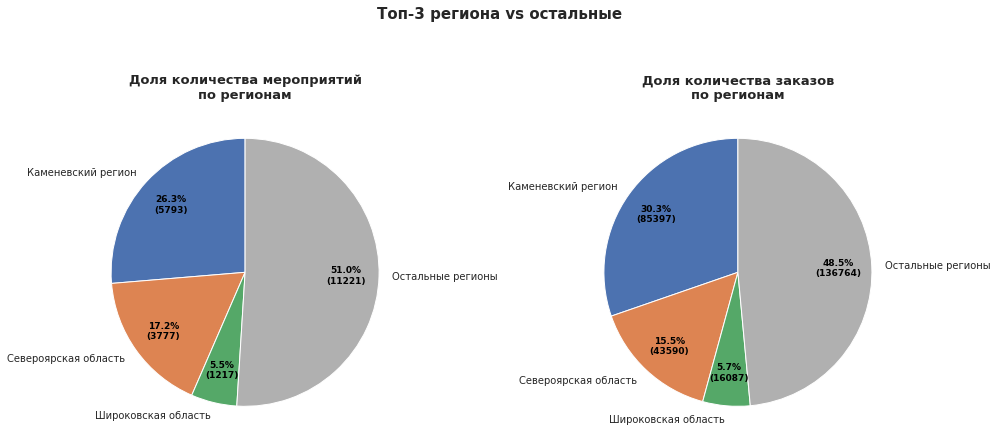

In [77]:
# Построение диаграмм
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# Диаграмма 1: Доля мероприятий
wedges1, texts1, autotexts1 = axes[0].pie(
    values_events,
    labels=labels_events,
    autopct=lambda pct: f'{pct:.1f}%\n({int(round(pct / 100 * sum(values_events)))})',
    colors=colors,
    startangle=90,
    pctdistance=0.75,
    textprops={'fontsize': 10}
)
axes[0].set_title('Доля количества мероприятий\nпо регионам', fontsize=13, fontweight='bold')

# Диаграмма 2: Доля заказов
wedges2, texts2, autotexts2 = axes[1].pie(
    values_orders,
    labels=labels_orders,
    autopct=lambda pct: f'{pct:.1f}%\n({int(round(pct / 100 * sum(values_orders)))})',
    colors=colors,
    startangle=90,
    pctdistance=0.75,
    textprops={'fontsize': 10}
)
axes[1].set_title('Доля количества заказов\nпо регионам', fontsize=13, fontweight='bold')

# Увеличиваем подписи снаружи
for t in texts1 + texts2:
    t.set_fontsize(10)
# Подписи внутри (проценты)
for t in autotexts1 + autotexts2:
    t.set_color('black')
    t.set_fontsize(9)
    t.set_fontweight('bold')

plt.suptitle('Топ-3 региона vs остальные', fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

* Каменевский регион — безоговорочный лидер по обеим метрикам: 26,3% всех мероприятий и 30,3% всех заказов. Причём его доля заказов выше доли мероприятий — это значит, что мероприятия здесь не только многочисленны, но и хорошо «конвертируются» в заказы. На одно мероприятие приходится 14,7 заказов — лучший показатель среди топ-регионов.
* Североярская область — уверенное второе место: 17,2% мероприятий и 15,5% заказов. Но заказов на мероприятие здесь 11,5 — ниже, чем у Каменевского и Широковского (13,2).
* Два региона из 81 обеспечивают почти половину всех мероприятий и заказов. А 76 регионов из «хвоста» делят между собой оставшиеся ~43%.

---

In [78]:
# Анализ по партнерам
partner_agg = (
    df
    .groupby('service_name', as_index=False)
    .agg(
        unique_events=('event_id', 'nunique'),
        total_orders=('order_id', 'count'),
        total_revenue_rub=('revenue_rub', 'sum')
    )
)

In [79]:
# Доли от общих значений
partner_agg['events_share_%'] = (partner_agg['unique_events'] / partner_agg['unique_events'].sum() * 100).round(2)
partner_agg['orders_share_%'] = (partner_agg['total_orders'] / partner_agg['total_orders'].sum() * 100).round(2)
partner_agg['revenue_share_%'] = (partner_agg['total_revenue_rub'] / partner_agg['total_revenue_rub'].sum() * 100).round(2)

In [80]:
# Сортировка по выручке
partner_result = partner_agg.sort_values('total_revenue_rub', ascending=False).reset_index(drop=True)

partner_result.head(7)

,service_name,unique_events,total_orders,total_revenue_rub,events_share_%,orders_share_%,revenue_share_%
0,Билеты без проблем,4019,57861,"24,325,047.63",16.72,20.53,16.30
1,Мой билет,1296,34426,"22,041,902.11",5.39,12.21,14.77
2,Облачко,2335,26402,"18,588,613.86",9.72,9.37,12.45
3,Лови билет!,4813,40504,"16,676,468.97",20.03,14.37,11.17
4,Весь в билетах,856,16426,"16,537,495.10",3.56,5.83,11.08
5,Билеты в руки,3486,39799,"13,193,924.37",14.50,14.12,8.84
6,Край билетов,252,6109,"6,405,689.22",1.05,2.17,4.29


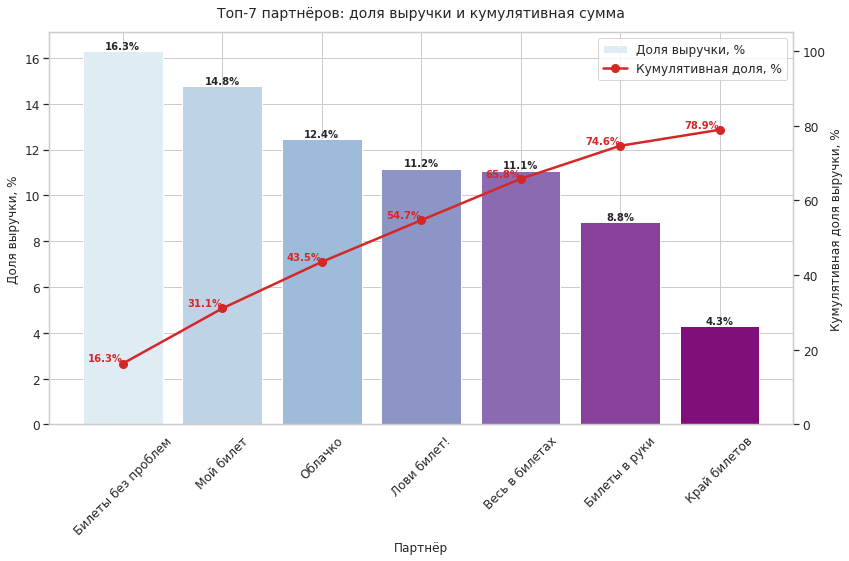

In [81]:
# Берём топ-7 партнёров по выручке
top_partners = partner_result.head(7).copy()

# Кумулятивная доля выручки (в процентах)
top_partners['cum_revenue_share_%'] = top_partners['revenue_share_%'].cumsum()

sns.set_style("whitegrid")
sns.set_context("notebook", font_scale=1.1)

fig, ax1 = plt.subplots(figsize=(12, 8))

# Столбцы: доля выручки по партнёру
bars = ax1.bar(
    top_partners['service_name'],
    top_partners['revenue_share_%'],
    color=sns.color_palette("BuPu", 7),
    label='Доля выручки, %'
)

ax1.set_ylabel('Доля выручки, %', fontsize=12)
ax1.set_xlabel('Партнёр', fontsize=12)
ax1.set_title('Топ‑7 партнёров: доля выручки и кумулятивная сумма', fontsize=14, pad=15)
ax1.tick_params(axis='x', rotation=45)

# Линия: кумулятивная доля
ax2 = ax1.twinx()
ax2.plot(
    top_partners['service_name'],
    top_partners['cum_revenue_share_%'],
    marker='o',
    color='#d62728',
    linewidth=2.5,
    markersize=8,
    label='Кумулятивная доля, %'
)
ax2.set_ylabel('Кумулятивная доля выручки, %', fontsize=12)
ax2.set_ylim(0, 105)  
ax2.grid(False)

# Подписи значений на столбцах
for bar in bars:
    height = bar.get_height()
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f'{height:.1f}%',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

# Подписи на линии кумулятивной доли
for i, val in enumerate(top_partners['cum_revenue_share_%']):
    ax2.text(
        i,
        val,
        f'{val:.1f}%',
        ha='right',
        va='bottom' if val < 90 else 'top',
        fontsize=10,
        color='#d62728',
        fontweight='bold'
    )

# Легенда (объединяем легенды осей)
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper right')

plt.tight_layout()
plt.show()

* Абсолютный лидер по ассортименту — «Лови билет!»: 20,03% всех мероприятий. Это самый широкий каталог среди партнёров. При этом его доля выручки — 11,17%, то есть он даёт много событий, но средний чек/конверсия ниже средней по рынку.
* Лидер по выручке — «Билеты без проблем»: 16,30% всей выручки при 16,72% мероприятий и 20,53% заказов. У него самая высокая доля заказов среди топ‑партнёров — значит, хорошая конверсия и/или много повторных покупок.
* «Мой билет» и «Облачко» — сильные середняки с высокой долей выручки (14,77% и 12,45%) при умеренном количестве мероприятий. Это признак более «дорогих» или лучше продаваемых событий.
* Топ‑3 партнёра («Билеты без проблем», «Мой билет», «Облачко») формируют 43,5 % выручки; топ‑5 — 65,8 %.

[Назад к содержанию](#start)

---

## Итоговый вывод и рекомендации
<a id='5.1'></a>
### Обзор проделанной работы

В ходе исследования были проанализированы данные о бронировании билетов на сервисе Яндекс Афиша за период с 1 июня по 31 октября 2024 года. Изучалось изменение пользовательской активности и интереса в связи с сезонностью. Была проведена последовательная очистка исходных данных от пропусков и дубликатов, также проведен исследовательский анализ для решения поставленных задач, а также статистический анализ данных для проверки гипотез о разнице в поведении пользователей с мобильными и стационарными устройствами.

<a id='5.2'></a>
### Ответы на исследовательские вопросы

***Сезонные изменения - лето & осень:***
* Рост заказов устойчивый, с выраженным всплеском в сентябре (+59,6 % к августу) и октябре (+43,7 % к сентябрю).
* Спрос перераспределяется между категориями: летом лидируют концерты и театр, осенью усиливается доля театра, спорта и категории «другое». Несмотря на изменения, концерты и театр остаются ключевыми сегментами, формирующими основную часть заказов.
* По соотношению устройств — стабильный паттерн: mobile доминирует (~80 %), доля desktop незначительно растёт осенью (до 20,4 %) — соотношение остаётся около 4:1.
* Смещение спроса в сторону семейного контента. Осенью растёт доля заказов с рейтингами «0+» и «12+», а доля «18+» снижается — это может говорить о сезонном изменении приоритетов аудитории: от «взрослого» досуга летом к семейному осенью.
* Средняя выручка с билета по большинству типов мероприятий снизилась осенью по сравнению с летом — наиболее заметно в сегментах «ёлки» (−15,1 %) и «концерты» (−13,5 %), при этом в категории «стендап» зафиксирован рост (с 219 до 231 руб.).

***Осенняя активность:***
* Наблюдается волатильность числа заказов с пиками в начале сентября и октября и последующим ростом к концу периода — вероятно, это связано с запуском промоакций, выходом новой афиши или возвращением аудитории к привычному ритму после лета.
* DAU устойчиво увеличивается: от ~600 в начале сентября до ~1300 к началу ноября.
* Активность пользователей выше в будни: там существенно больше и объём заказов, и DAU, и интенсивность использования (9,67 заказа на пользователя против 5,71 в выходные). Это согласуется с типичным поведением аудитории: в рабочие дни пользователи чаще просматривают афишу и совершают покупки в перерывах, а также могут планировать мероприятия на будущее.
* Средний чек в выходные заметно выше (197 руб. против 173 руб.), что может быть особенностями ценообразования (акции и скидки активнее применяются в будни). 

***Ключевые регионы и партнёры:***
* Спрос сильно сконцентрирован в топовых регионах — два из них обеспечивают почти половину всех мероприятий и заказов (Каменевский регион и Североярская область). Основная масса регионов (76 из 81) формирует лишь около 43 % мероприятий.
* Рынок заметно сконцентрирован, значительная часть выручки генерируется небольшой группой ключевых партнёров: топ‑3 формируют 43,5 % выручки, топ‑5 — 65,8 %. 

<a id='5.4'></a>
### Рекомендации на основе анализа данных

* Фокус разработки и удержания — на мобильном приложении (пуши, персонализация, быстрые действия). Desktop поддерживать для «планирующих» сценариев.
* Планировать промо и расширение афиши под семейный и спортивный досуг; отдельно проработать стратегию для сегмента «18+».
* Акции и скидки — в будни; в выходные продвигать более дорогие события и пакеты билетов.
* Изучить практики Каменевского региона и тиражировать их в регионах с высокой базой мероприятий, но низкой конверсией (Светополянский, Речиновская).
* Повысить эффективность партнёра «Лови билет!» — внедрить меры по росту конверсии/среднего чека. Анализировать нишевых партнёров («Весь в билетах», «Край билетов») отдельно. Дать инструменты роста менее крупным партнёрам (обучения работе с платформой или точечные промо).

[Назад к содержанию](#start)